# TradePulse - Steps 3 & 4: Target Definition & Chronological Split Protocol
**IIT Patna, IMPACT Lab | End-to-End Machine Learning Guidelines**  
**Asset:** META (NASDAQ) | **Timeframe:** 5-minute | **Horizon:** 15-minute (3 bars ahead)  

---
### Objectives
1. **Chronological Split Derivation:** Derive exact calendar trading-day and bar counts using `pandas-market-calendars` (incorporating 1-day embargo buffers).
2. **Target Computation:** Compute 3-bar forward returns strictly within each trading session ($R_{t, t+3} = \frac{Close_{t+3}}{Close_t} - 1$), dropping the final 3 bars of every session.
3. **Target Quality Audit:** Track and report whether any labels depend on forward-filled $t+3$ bars (`target_is_filled`).
4. **Threshold Selection Grid (Train-Only):** Compute candidate threshold rules (Fixed, Symmetric Quantiles of $|R|$, and Causal Volatility-Adaptive) strictly on training data.
5. **Class Balance Comparison:** Report empirical class distributions (Up, Neutral, Down) for each candidate threshold without leakage.

In [1]:
import sys
import os
import json
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_market_calendars as mcal

from ml.preprocessing import PROCESSED_CSV_PATH, EXCHANGE_TIMEZONE
from ml.targets import (
    compute_forward_returns,
    compute_candidate_thresholds,
    assign_labels_for_rule,
    FROZEN_THRESHOLDS_PATH,
)

sns.set_theme(style="whitegrid", palette="muted")
print("Target pipeline modules loaded successfully from ml/")

Target pipeline modules loaded successfully from ml/


## 1. Calendar Derivation of Split Boundaries (Step 4)
Per our strict protocol, day and bar counts are dynamically derived from the official NASDAQ exchange schedule, not hardcoded.

In [2]:
nasdaq = mcal.get_calendar("NASDAQ")

split_definitions = {
    "Train": ("2025-11-03", "2026-06-30", False),
    "Embargo 1": ("2026-07-01", "2026-07-01", True),
    "Validation": ("2026-07-02", "2026-08-31", False),
    "Embargo 2": ("2026-09-01", "2026-09-01", True),
    "Test (Touched Once)": ("2026-09-02", "2026-11-06", False),
}

split_rows = []
for split_name, (start_dt, end_dt, is_embargo) in split_definitions.items():
    sched = nasdaq.schedule(start_date=start_dt, end_date=end_dt)
    bar_count = 0
    half_days = 0
    for _, srow in sched.iterrows():
        daily_bars = pd.date_range(srow["market_open"], srow["market_close"] - pd.Timedelta(minutes=5), freq="5min")
        bar_count += len(daily_bars)
        if len(daily_bars) < 78:
            half_days += 1
            
    dropped_eod = len(sched) * 3
    valid_targets = bar_count - dropped_eod
    
    split_rows.append({
        "Split": split_name,
        "Start Date": start_dt,
        "End Date": end_dt,
        "Trading Days": len(sched),
        "Half-Days": half_days,
        "Total Bars": bar_count,
        "Dropped EOD Bars": dropped_eod,
        "Valid Target Bars": valid_targets,
    })

split_table = pd.DataFrame(split_rows)
print(split_table.to_string(index=False))
print(f"\nTotal trading sessions across dataset: {split_table['Trading Days'].sum()}")
print(f"Total bars across dataset: {split_table['Total Bars'].sum():,}")

              Split Start Date   End Date  Trading Days  Half-Days  Total Bars  Dropped EOD Bars  Valid Target Bars
              Train 2025-11-03 2026-06-30           164          2       12720               492              12228
          Embargo 1 2026-07-01 2026-07-01             1          0          78                 3                 75
         Validation 2026-07-02 2026-08-31            42          0        3276               126               3150
          Embargo 2 2026-09-01 2026-09-01             1          0          78                 3                 75
Test (Touched Once) 2026-09-02 2026-11-06            47          0        3666               141               3525

Total trading sessions across dataset: 255
Total bars across dataset: 19,818


## 2. 3-Bar Forward Return Computation & Quality Audit
Returns are computed strictly within each session: $R_{t, t+3} = \frac{Close_{t+3}}{Close_t} - 1$. The last 3 bars of every session are marked `valid_target=False`.

In [3]:
clean_df = pd.read_csv(PROCESSED_CSV_PATH)
labeled_df = compute_forward_returns(clean_df, horizon_bars=3)

print(f"Clean processed bars read: {len(labeled_df):,}")
print(f"Valid target bars: {labeled_df['valid_target'].sum():,}")
print(f"Dropped end-of-day rows: {(~labeled_df['valid_target']).sum():,}")
print(f"Targets depending on forward-filled t+3 bar: {(labeled_df['target_is_filled'] == 1).sum():,}")

# Confirm that exactly 3 bars per day are dropped
days_count = labeled_df['session_date'].nunique()
assert (~labeled_df['valid_target']).sum() == days_count * 3
print(f"Audit Check Passed: Exactly 3 bars dropped per session ({days_count} days * 3 = {days_count * 3} dropped).")

Clean processed bars read: 19,818
Valid target bars: 19,053
Dropped end-of-day rows: 765
Targets depending on forward-filled t+3 bar: 0
Audit Check Passed: Exactly 3 bars dropped per session (255 days * 3 = 765 dropped).


## 3. Training Set Isolation & Forward Return Characteristics
All decisions regarding candidate thresholds $\theta$ are restricted strictly to the training partition (Nov 3, 2025 to Jun 30, 2026).

In [4]:
train_mask = (labeled_df["session_date"].astype(str) >= "2025-11-03") & \
             (labeled_df["session_date"].astype(str) <= "2026-06-30") & \
             labeled_df["valid_target"]

train_df = labeled_df[train_mask].copy()
r_train = train_df["target_return"]
abs_r_train = r_train.abs()

print("=== Training Set 15-Minute Forward Return Distribution ===")
print(f"Total training observations: {len(train_df):,}")
print(f"Mean return                : {r_train.mean() * 100:.4f}%")
print(f"Std deviation              : {r_train.std() * 100:.3f}%")
print(f"Min / Max return           : [{r_train.min() * 100:.2f}%, {r_train.max() * 100:.2f}%]")
print(f"Median |R|                 : {abs_r_train.median() * 100:.4f}%")
print(f"40th Percentile |R|        : {abs_r_train.quantile(0.40) * 100:.4f}%")
print(f"60th Percentile |R|        : {abs_r_train.quantile(0.60) * 100:.4f}%")

=== Training Set 15-Minute Forward Return Distribution ===
Total training observations: 12,228
Mean return                : 0.0013%
Std deviation              : 0.295%
Min / Max return           : [-3.93%, 3.06%]
Median |R|                 : 0.1472%
40th Percentile |R|        : 0.1134%
60th Percentile |R|        : 0.1896%


## 4. Candidate Threshold Grid Computation (Train Data Only)
We compute and freeze the predefined threshold parameter candidates into `artifacts/metadata/target_thresholds.json`.

In [5]:
frozen_params = compute_candidate_thresholds(train_df)
print(f"Frozen threshold configuration saved to: {FROZEN_THRESHOLDS_PATH}\n")
print(json.dumps(frozen_params, indent=2))

Frozen threshold configuration saved to: E:\Projects\Trading Project\TradePulse\artifacts\metadata\target_thresholds.json

{
  "fixed_rules": {
    "fixed_10bp": {
      "theta": 0.001,
      "description": "Fixed cut at +/-0.10% (10 bps)"
    },
    "fixed_15bp": {
      "theta": 0.0015,
      "description": "Fixed cut at +/-0.15% (15 bps)"
    },
    "fixed_20bp": {
      "theta": 0.002,
      "description": "Fixed cut at +/-0.20% (20 bps)"
    }
  },
  "quantile_rules": {
    "quantile_40": {
      "percentile": 40,
      "theta": 0.0011340497018420327,
      "description": "Symmetric 40th percentile of |R_train| (0.1134%)"
    },
    "quantile_50": {
      "percentile": 50,
      "theta": 0.0014721634849290122,
      "description": "Symmetric 50th percentile (median) of |R_train| (0.1472%)"
    },
    "quantile_60": {
      "percentile": 60,
      "theta": 0.0018957250188708751,
      "description": "Symmetric 60th percentile of |R_train| (0.1896%)"
    }
  },
  "volatility_rules":

## 5. Class Balance Comparison Across Candidate Rules (Train Only)
Evaluating class distributions across Fixed, Symmetric Quantiles of $|R|$, and Causal Volatility-Adaptive rules.

In [6]:
candidate_eval_rows = []

# 1. Fixed Rules
for rname, rcfg in frozen_params["fixed_rules"].items():
    labels = assign_labels_for_rule(train_df, "fixed", rname, frozen_params)
    up_pct = (labels == 1.0).mean() * 100.0
    down_pct = (labels == -1.0).mean() * 100.0
    neutral_pct = (labels == 0.0).mean() * 100.0
    candidate_eval_rows.append({
        "Rule Group": "Fixed Return",
        "Rule Name": rname,
        "Theta Parameter": f"+/- {rcfg['theta'] * 100:.2f}%",
        "Up (+1) %": f"{up_pct:.1f}%",
        "Neutral (0) %": f"{neutral_pct:.1f}%",
        "Down (-1) %": f"{down_pct:.1f}%",
    })

# 2. Quantile Rules
for rname, rcfg in frozen_params["quantile_rules"].items():
    labels = assign_labels_for_rule(train_df, "quantile", rname, frozen_params)
    up_pct = (labels == 1.0).mean() * 100.0
    down_pct = (labels == -1.0).mean() * 100.0
    neutral_pct = (labels == 0.0).mean() * 100.0
    candidate_eval_rows.append({
        "Rule Group": "Symmetric Quantile of |R|",
        "Rule Name": rname,
        "Theta Parameter": f"+/- {rcfg['theta'] * 100:.4f}%",
        "Up (+1) %": f"{up_pct:.1f}%",
        "Neutral (0) %": f"{neutral_pct:.1f}%",
        "Down (-1) %": f"{down_pct:.1f}%",
    })

# 3. Volatility Rules
for rname, rcfg in frozen_params["volatility_rules"].items():
    labels = assign_labels_for_rule(train_df, "volatility", rname, frozen_params)
    up_pct = (labels == 1.0).mean() * 100.0
    down_pct = (labels == -1.0).mean() * 100.0
    neutral_pct = (labels == 0.0).mean() * 100.0
    candidate_eval_rows.append({
        "Rule Group": "Causal Volatility-Adaptive",
        "Rule Name": rname,
        "Theta Parameter": f"{rcfg['k']:.2f} * sigma_3b (floor 0.08%)",
        "Up (+1) %": f"{up_pct:.1f}%",
        "Neutral (0) %": f"{neutral_pct:.1f}%",
        "Down (-1) %": f"{down_pct:.1f}%",
    })

candidate_summary_df = pd.DataFrame(candidate_eval_rows)
print(candidate_summary_df.to_string(index=False))

                Rule Group   Rule Name               Theta Parameter Up (+1) % Neutral (0) % Down (-1) %
              Fixed Return  fixed_10bp                     +/- 0.10%     32.0%         36.1%       31.9%
              Fixed Return  fixed_15bp                     +/- 0.15%     24.4%         50.8%       24.8%
              Fixed Return  fixed_20bp                     +/- 0.20%     18.9%         62.2%       18.9%
 Symmetric Quantile of |R| quantile_40                   +/- 0.1134%     30.0%         40.0%       30.0%
 Symmetric Quantile of |R| quantile_50                   +/- 0.1472%     24.8%         50.0%       25.2%
 Symmetric Quantile of |R| quantile_60                   +/- 0.1896%     20.0%         60.0%       20.0%
Causal Volatility-Adaptive    vol_k050 0.50 * sigma_3b (floor 0.08%)     28.6%         42.5%       28.9%
Causal Volatility-Adaptive    vol_k075 0.75 * sigma_3b (floor 0.08%)     21.3%         57.0%       21.7%
Causal Volatility-Adaptive    vol_k100 1.00 * sigma_3b 

## 6. Forward Return Distribution & Threshold Visualizations

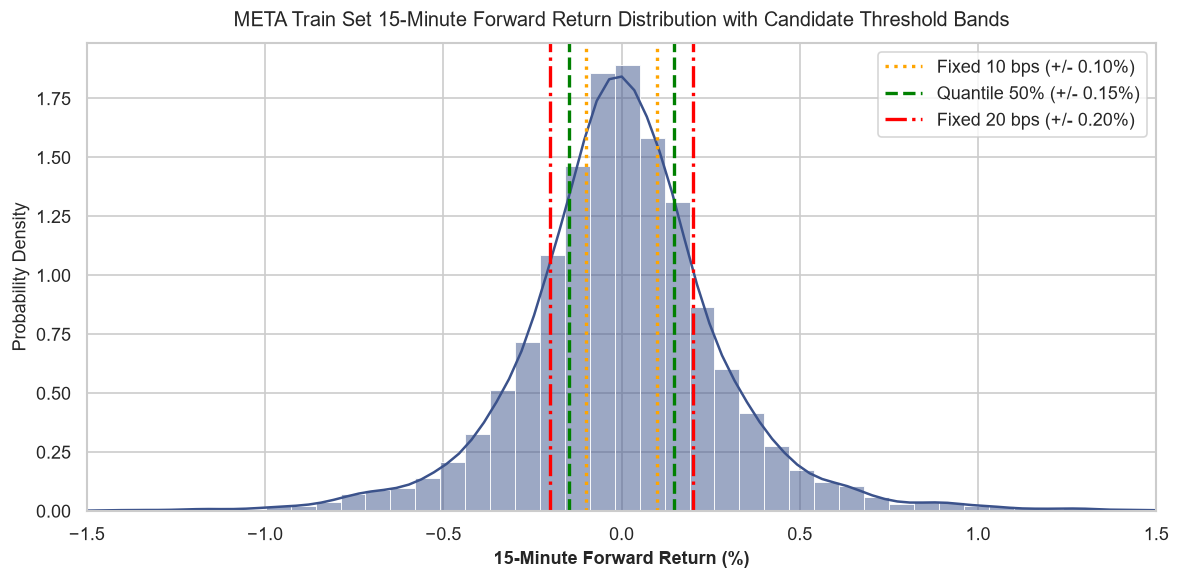

In [7]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
returns_pct = r_train * 100.0
sns.histplot(returns_pct, bins=100, kde=True, color="#3b528b", stat="density", ax=ax, alpha=0.5)

# Overlay candidate threshold bands
th_10 = frozen_params["fixed_rules"]["fixed_10bp"]["theta"] * 100.0
th_q50 = frozen_params["quantile_rules"]["quantile_50"]["theta"] * 100.0
th_20 = frozen_params["fixed_rules"]["fixed_20bp"]["theta"] * 100.0

ax.axvline(th_10, color="orange", linestyle=":", linewidth=2, label=f"Fixed 10 bps (+/- {th_10:.2f}%)")
ax.axvline(-th_10, color="orange", linestyle=":", linewidth=2)
ax.axvline(th_q50, color="green", linestyle="--", linewidth=2, label=f"Quantile 50% (+/- {th_q50:.2f}%)")
ax.axvline(-th_q50, color="green", linestyle="--", linewidth=2)
ax.axvline(th_20, color="red", linestyle="-.", linewidth=2, label=f"Fixed 20 bps (+/- {th_20:.2f}%)")
ax.axvline(-th_20, color="red", linestyle="-.", linewidth=2)

ax.set_xlim(-1.5, 1.5)
ax.set_xlabel("15-Minute Forward Return (%)", fontsize=11, fontweight="bold")
ax.set_ylabel("Probability Density", fontsize=11)
ax.set_title("META Train Set 15-Minute Forward Return Distribution with Candidate Threshold Bands", fontsize=12, pad=10)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "target_return_distribution_bands.png")
plt.show()

## 7. Class Balance Breakdown Chart

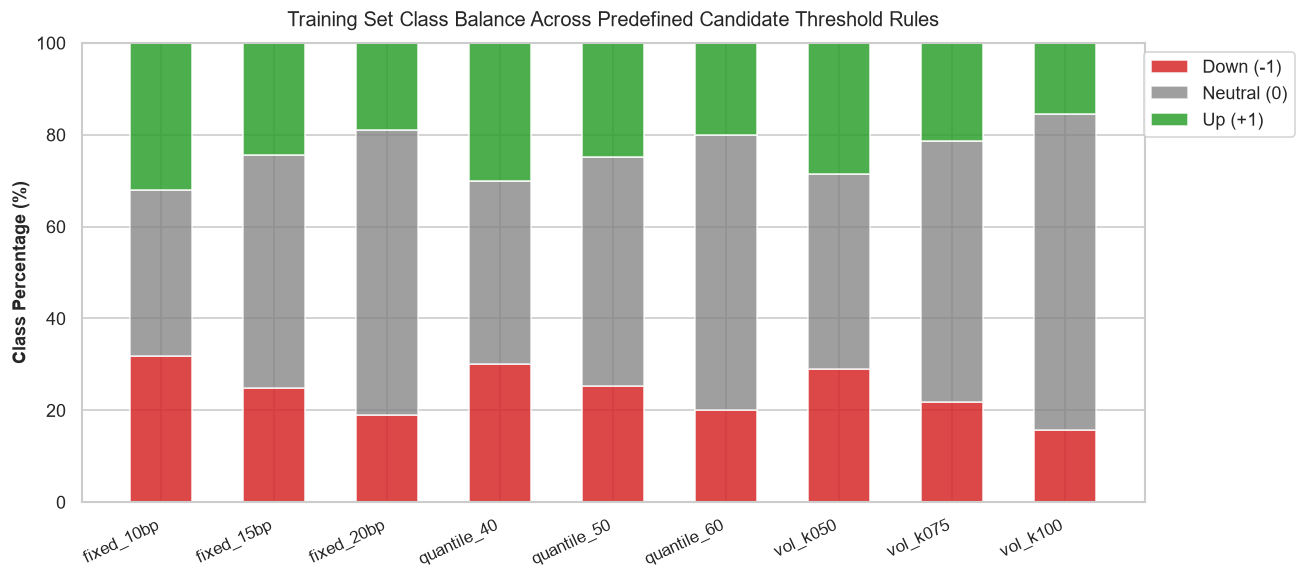

In [8]:
plot_df = candidate_summary_df.copy()
plot_df["Up"] = plot_df["Up (+1) %"].str.rstrip("%").astype(float)
plot_df["Neutral"] = plot_df["Neutral (0) %"].str.rstrip("%").astype(float)
plot_df["Down"] = plot_df["Down (-1) %"].str.rstrip("%").astype(float)

fig, ax = plt.subplots(figsize=(11, 5), dpi=120)
x = np.arange(len(plot_df))
width = 0.55

b1 = ax.bar(x, plot_df["Down"], width, label="Down (-1)", color="#d62728", alpha=0.85)
b2 = ax.bar(x, plot_df["Neutral"], width, bottom=plot_df["Down"], label="Neutral (0)", color="#7f7f7f", alpha=0.75)
b3 = ax.bar(x, plot_df["Up"], width, bottom=plot_df["Down"] + plot_df["Neutral"], label="Up (+1)", color="#2ca02c", alpha=0.85)

ax.set_ylabel("Class Percentage (%)", fontsize=11, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Rule Name"], rotation=25, ha="right", fontsize=10)
ax.set_ylim(0, 100)
ax.set_title("Training Set Class Balance Across Predefined Candidate Threshold Rules", fontsize=12, pad=10)
ax.legend(loc="upper right", bbox_to_anchor=(1.15, 1.0))
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "candidate_rules_class_balance.png")
plt.show()